In [305]:
#Functions
import numpy as np
import netCDF4
import cycler
import certifi
import os
import matplotlib.pyplot as plt
import scipy.stats
import glob
from scipy.signal import detrend
os.environ["PROJ_LIB"] = "C:\\Utilities\\Python\\Anaconda\\Library\\share"; #fixr
from mpl_toolkits.basemap import Basemap
import warnings
warnings.filterwarnings("ignore")
from matplotlib.colors import BoundaryNorm
import matplotlib.colors as colors
from matplotlib.colors import Normalize
def has_number(string):
  return any(char.isdigit() for char in string)
Base_c96 = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/GPCP_c96.nc')    
lats_c96,lons_c96 = Base_c96.variables['lat'][:],Base_c96.variables['lon'][:]
Base_c192 = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/North American Precip/Data/ATMOS_STATIC/ControlTopo.atmos.static.nc')
lats,lons = Base_c192.variables['lat'][:],Base_c192.variables['lon'][:]
lats_c192,lons_c192 = Base_c192.variables['lat'][:],Base_c192.variables['lon'][:]

def GetGPCP_TS(Months,Years):
        Data = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/GPCP_c96.nc')    
        Tinds = []
        YearJanInds = (Years-1979)*12
        for YearJanInd in YearJanInds:
            for Month in Months:
                Tinds.append(YearJanInd+Month)
        TS = np.zeros((len(Years),len(lats_c96),len(lons_c96)))
        for Year in range(len(Years)):
            YearInds = Tinds[Year*len(Months):Year*len(Months)+len(Months)]
            TS[Year] = np.mean(Data.variables['precip'][YearInds],axis=0)        
        return TS


def GetERA5_TS(VarName,Lev,Months,Years):
    MonthLengths = np.array([31,28,31,30,31,30,31,31,30,31,30,31])
    ndays = np.sum(MonthLengths[Months])
    MonthWeights = MonthLengths[Months]/ndays

    Tinds = []
    for Year in Years:
        for Month in Months:
            Tinds.append((Year-1979)*12+Month)
    if VarName == 'msl' or VarName == 't2m':
        Data = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/ERA5/1979-2025/msl_t2m_c96.nc')
    elif VarName == 'sshf' or VarName == 'slhf':
        Data = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/ERA5/1979-2025/sshf_slhf_c96.nc')
    else:
        Data = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/ERA5/1979-2025/'+VarName+'_c96.nc')
    TS = np.zeros((len(Years),len(lats_c96),len(lons_c96)))
    if Lev == 'SFC':
        for Year in range(len(Years)):
            YearInds = Tinds[Year*len(Months):Year*len(Months)+len(Months)]
            n=0
            TS_Year = np.zeros((len(lats_c96),len(lons_c96)))
            for MonthInd in YearInds:
                MonthWeight = MonthWeights[n]
                n+=1
                TS_Year = TS_Year + Data.variables[VarName][MonthInd]*MonthWeight
            TS[Year] = TS_Year
    else: 
        VarName = VarName[0]
        for Year in range(len(Years)):
            YearInds = Tinds[Year*len(Months):Year*len(Months)+len(Months)]
            n=0
            TS_Year = np.zeros((len(lats_c96),len(lons_c96)))
            for MonthInd in YearInds:
                MonthWeight = MonthWeights[n]
                n+=1
                TS_Year = TS_Year + Data.variables[VarName][MonthInd,0]*MonthWeight
            TS[Year] = TS_Year
    return TS

def GetCMIP6_100km_TS(Model,VarName,PresentYears,Months,Lev):
    SPEAR_CMIP6_Vars = { "precip": "pr","sst":"tos","slp":"psl","z":"zg","u":"ua","v":"va","t_ref":"tas","evap":"evspsbl","t":"ta","shflx":"hfss","lhflx":"hfls",
                       "swup_sfc":"rsus","swdn_sfc":"rsds","lwup_sfc":"rlus","lwdn_sfc":"rlds","tcc":"clt","hfds":"hfds"}
    if "air_temperature" in VarName:
        VarName_CMIP6 = 'ta'
    elif has_number(VarName)==True:
        VarName_FirstLetter = VarName[0]
        VarName_CMIP6 = SPEAR_CMIP6_Vars[VarName_FirstLetter]
    else: 
        VarName_CMIP6 = SPEAR_CMIP6_Vars[VarName]

    CMIP6_Path = '/Users/benjaminjohnson/Desktop/Postdoc Research/Data/CMIP6/100km/'
    Data = netCDF4.Dataset(CMIP6_Path+Model+'/'+VarName+'_c96.nc')

    TimeInds = []
    for Year in Years-2015:
        for Month in Months:
            TimeInds.append(Year*12+Month)
    TimeSeries = np.zeros((len(Years),len(lats_c96),len(lons_c96)))
    YearNum = 0
    if Lev == 'SFC':
        for Year in Years-2015:
            YearTimeInds = TimeInds[Year*len(Months):Year*len(Months)+len(Months)]
            YearMean = np.mean(Data.variables[VarName_CMIP6][YearTimeInds],axis=0)
            TimeSeries[YearNum] = YearMean
            YearNum += 1
    else:
        for Year in Years-2015:
            YearTimeInds = TimeInds[Year*len(Months):Year*len(Months)+len(Months)]
            YearMean = np.mean(Data.variables[VarName_CMIP6][YearTimeInds,0],axis=0)
            TimeSeries[YearNum] = YearMean
            YearNum += 1
    return TimeSeries
def GetCMIP6_100km_TS_MultiModelMean(Models,VarName,PresentYears,Months,Lev):
    MultiModelTS_Sum = np.zeros((len(Years),len(lats_c96),len(lons_c96)))
    for Model in Models: 
        TS = GetCMIP6_100km_TS(Model,VarName,PresentYears,Months,Lev)
        MultiModelTS_Sum += TS
    MultiModelTS_Mean = MultiModelTS_Sum/len(Models)
    return MultiModelTS_Mean


def GetCMIP6_100km_Historical_TS(Model,VarName,Years,Months,Lev):
    SPEAR_CMIP6_Vars = { "precip": "pr","sst":"tos","slp":"psl","z":"zg","u":"ua","v":"va","t_ref":"tas","evap":"evspsbl","precipitation":"pr",
                       "surface_upward_sensible_heat_flux":"hfss","surface_upward_latent_heat_flux":"hfls","surface_downwelling_shortwave_radiation":"rsds",
                       "surface_downwelling_longwave_radiation":"rlds","surface_upwelling_shortwave_radiation":"rsus","surface_upwelling_longwave_radiation":"rlus",
                       "wap":"wap","zg":"zg","hfds":"hfds"}
    VarFileName_Key = {"t_ref":"near_surface_air_temperature","slp":"sea_level_pressure","precipitation":"precipitation",
                      "surface_upward_sensible_heat_flux":"surface_upward_sensible_heat_flux","surface_upward_latent_heat_flux":"surface_upward_latent_heat_flux",
                      "surface_downwelling_shortwave_radiation":"surface_downwelling_shortwave_radiation","surface_downwelling_longwave_radiation":"surface_downwelling_longwave_radiation",
                       "surface_upwelling_shortwave_radiation":"surface_upwelling_shortwave_radiation","surface_upwelling_longwave_radiation":"surface_upwelling_longwave_radiation","hfds":"hfds"}
    Var = { "precip": "pr","sst":"tos","slp":"psl","z":"zg","u":"ua","v":"va","t_ref":"tas","evap":"evspsbl","wap":"wap","zg":"zg"}
    VarName_CMIP6 = SPEAR_CMIP6_Vars[VarName]
    if has_number(VarName)==True:
        VarFileName = VarName+'_c96'
        if "air_temperature" in VarName:
            VarName_CMIP6 = 'ta'
        else:
            VarName_FirstLetter = VarName[0]
            VarName_CMIP6 = SPEAR_CMIP6_Vars[VarName_FirstLetter]
    import glob
    if Lev == 'SFC':
        VarFileName = VarFileName_Key[VarName]+'_c96'
        CMIP6_Historical_Path = '/Users/benjaminjohnson/Desktop/Postdoc Research/Data/CMIP6_Historical/100km/'
        Data = netCDF4.Dataset(CMIP6_Historical_Path+Model+'/'+VarFileName+'.nc')
    else:
        FileStart = VarName+Lev
        VarFileName = (glob.glob('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/CMIP6_Historical/100km/'+Model+'/'+FileStart+'*.nc'))[0]
        Data = netCDF4.Dataset(VarFileName)
    time = Data.variables['time'][:]

    TimeInds = []
    for Year in Years-2014:
        for Month in Months:
            TimeInds.append((Year-1)*12+Month)
    TimeSeries = np.zeros((len(Years),len(lats_c96),len(lons_c96)))
    YearNum = 0
    if Lev == 'SFC':
        for Year in Years-Years[0]:
            YearTimeInds = TimeInds[Year*len(Months):Year*len(Months)+len(Months)]
            YearMean = np.mean(Data.variables[VarName_CMIP6][YearTimeInds],axis=0)
            TimeSeries[YearNum] = YearMean
            YearNum += 1
    else: 
        for Year in Years-Years[0]:
            YearTimeInds = TimeInds[Year*len(Months):Year*len(Months)+len(Months)]
            YearMean = np.mean(Data.variables[VarName_CMIP6][YearTimeInds,0],axis=0)
            TimeSeries[YearNum] = YearMean
            YearNum += 1
    return TimeSeries
def GetCMIP6_100km_Historical_TS_MultiModelMean(Models,VarName,Years,Months,Lev):
    MultiModelSum = np.zeros((len(Years),len(lats_c96),len(lons_c96)))
    for Model in Models:
        ModelTS = GetCMIP6_100km_Historical_TS(Model,VarName,Years,Months,Lev)
        MultiModelSum+=ModelTS
    MultiModelMean = MultiModelSum/len(Models)
    return MultiModelMean

    
def Get4xCO2(Model,VarName,Months,Years,Lev):
    if Lev == 'SFC':
        Path = '/Users/benjaminjohnson/Desktop/Postdoc Research/Data/Abrupt_4xCO2/100km/'+Model+'/'
        Data = netCDF4.Dataset(Path+VarName+'_000101-010012.nc')
    else:
        FileStart = VarName+Lev
        VarFileName = (glob.glob('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/Abrupt_4xCO2/100km/'+Model+'/'+FileStart+'*.nc'))[0]
        Data = netCDF4.Dataset(VarFileName)
    SPEAR_CMIP6_Vars = { "precip": "pr","sst":"tos","slp":"psl","z":"zg","u":"ua","v":"va","t_ref":"tas","evap":"evspsbl","t":"ta","shflx":"hfss","lhflx":"hfls",
                       "swup_sfc":"rsus","swdn_sfc":"rsds","lwufp_sfc":"rlus","lwdn_sfc":"rlds","tcc":"clt","hfds":"hfds","wap":"wap","zg":"zg"}
    VarName_CMIP = SPEAR_CMIP6_Vars[VarName]
    AnnualMeans = np.zeros((len(Years),len(lats_c96),len(lons_c96)))
    n=0
    if Lev == 'SFC':
        for Year in Years:
            Tstart,Tend = Year*12+Months[0],Year*12+Months[-1]
            AnnualMeans[n] = np.mean(Data.variables[VarName_CMIP][Tstart:Tend+1],axis=0)
            n+=1
    else: 
        for Year in Years:
            Tstart,Tend = Year*12+Months[0],Year*12+Months[-1]
            AnnualMeans[n] = np.mean(Data.variables[VarName_CMIP][Tstart:Tend+1,0],axis=0)
            n+=1
    return AnnualMeans
def Get4xCO2_MultiModelMean(Models,VarName,Months,Years,Lev):
    MultiModelTS_Sum = np.zeros((len(Years),len(lats_c96),len(lons_c96)))
    for Model in Models: 
        TS = Get4xCO2(Model,VarName,Months,Years,Lev)
        MultiModelTS_Sum += TS
    MultiModelTS_Mean = MultiModelTS_Sum/len(Models)
    return MultiModelTS_Mean


def GetMonthMean_SPEAR(Exp,VarName,Lev,Months):
        MonthLengths = np.array([31,28.25,31,30,31,30,31,31,30,31,30,31])
        os.chdir('/Users/benjaminjohnson/Desktop/North American Precip/Data/SPEAR_AV/100YearMonthlyAv/'+Exp)
        VarFiles = [] 
        MonthLengths2 = []
        for Month in Months:
            VarFiles.extend(sorted(glob.glob('*'+Month+'.nc')))
            MonthInd = int(Month)-1
            MonthLength = MonthLengths[MonthInd]
            MonthLengths2.append(MonthLength)
        MonthLengths2 = np.array(MonthLengths2)
        MonthMultipliers = []
        Ndays_Total = np.sum(MonthLengths2)
        for Month in range(len(Months)):
            MonthMultipliers.append(MonthLengths2[Month]/Ndays_Total)
        VarData = np.zeros((len(lats_c192),len(lons_c192)))
        for Month in range(len(VarFiles)):
            MonthMultiplier = MonthMultipliers[Month]
            FileData = netCDF4.Dataset('atmos.0001-0100.'+Months[Month]+'.nc')
            if Lev == 'SFC':
                VarData = VarData+(FileData.variables[VarName][0])*MonthMultiplier
            else:
                Levs = FileData.variables['level'][:]
                LevInd = np.argmin(np.abs(Levs-Lev))
                VarData = VarData+(FileData.variables[VarName][0,LevInd])*MonthMultiplier
        return VarData

def GetGlobalMean_c96(Data):
    Static = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/SPEAR/atmos.c96.static.nc')
    Areas = Static.variables['area'][:]
    AreaSum = np.sum(Areas)
    AreaFracs = Areas/AreaSum
    GlobalMean = np.sum(Data*AreaFracs)
    return GlobalMean

def GetRegression(Data3D,Data1D):
    import scipy.stats
    import numpy.ma as ma
    nLats = len(Data3D[0])
    nLons = len(Data3D[0,0])
    Pvals = np.zeros((nLats,nLons))
    Slopes = np.zeros((nLats,nLons))
    for lat in range(nLats):
        for lon in range(nLons):
            LatLonData = Data3D[:,lat,lon]
            LatLonData = np.ma.filled(LatLonData.astype(float), np.nan)
            if LatLonData[0] == np.nan:
                continue
            if len(set(LatLonData)) == 1:
                Pvals[lat,lon] = np.nan
                Slopes[lat,lon] = np.nan
                continue
            slope, intercept, r, p, se = scipy.stats.linregress(Data1D,LatLonData)
            Slopes[lat,lon] = slope
            Pvals[lat,lon] = p
    return Slopes,Pvals




Static_c96 = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/SPEAR/atmos.c96.static.nc')
Areas = Static_c96.variables['area'][:]
LandMask = Static_c96.variables['land_mask'][:]
LandNans = LandMask.copy()
LandNans[np.where(LandNans>0.5)]=np.nan
LandNans = LandNans-LandNans
LandMask = Static_c96.variables['land_mask'][:]
OceanNans = LandMask.copy()
OceanNans[np.where(OceanNans<0.5)]=np.nan
OceanNans = OceanNans-OceanNans
LatHigh = 70
LatS_Ind,LatN_Ind = np.argmin(np.abs(lats_c96+LatHigh)),np.argmin(np.abs(lats_c96-LatHigh))

LatsHigh_Nans = np.zeros((len(lats_c96),len(lons_c96)))
LatsHigh_Nans[:LatS_Ind] = np.nan
LatsHigh_Nans[LatN_Ind:] = np.nan
def GetGlobalMean_c96_LandSea(Data):
    Static = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/SPEAR/atmos.c96.static.nc')
    Data_Nans = Data-Data
    Areas = Static.variables['area'][:]+Data_Nans
    AreaSum = np.nansum(Areas)
    AreaFracs = Areas/AreaSum
    GlobalMean = np.nansum(Data*AreaFracs)
    return GlobalMean

def GetGlobalMean_c96_LatBounds(Data,LatBound):
    Static = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/SPEAR/atmos.c96.static.nc')
    Areas = Static.variables['area'][:]
    LatInd_Low = np.argmin(np.abs(lats_c96+LatBound))
    LatInd_High =  np.argmin(np.abs(lats_c96-LatBound))
    print(LatInd_High)
    print(LatInd_Low)
    Areas[:LatInd_Low] = 0
    Areas[LatInd_High:] = 0
    AreaSum = np.sum(Areas)
    AreaFracs = Areas/AreaSum
    GlobalMean = np.sum(Data*AreaFracs)
    return GlobalMean

def TS_SpatialSmoothing(TS,nGridBoxes):
    TS_Smoothed = TS.copy()
    for lat in range(nGridBoxes,TS.shape[1]-nGridBoxes):
        for lon in range(nGridBoxes,TS.shape[2]-nGridBoxes):
            LatLonBoxMean = np.mean(TS[:,lat-nGridBoxes:lat+nGridBoxes+1,lon-nGridBoxes:lon+nGridBoxes+1],axis=(1,2))
            TS_Smoothed[:,lat,lon] = LatLonBoxMean
    return TS_Smoothed


import cmaps
#Figure 2
Months = [0,1,2,3,4,5,6,7,8,9,10,11]
Years = np.arange(1979,2020,1)

def read_hadslp_ascii(filepath, nlon=72, nlat=36, missing_val=102864):
    data = []
    times = []
    n = 0
    with open(filepath, 'r') as f:
        lines = f.readlines()
    DataArray = np.zeros((len(range(0,2204*12*38,38)),36,72))    
    for i in range(0,77520,38):
        header = lines[i].split()
        YearMonthData = np.zeros((36,72))
        #for line in range(1,38):
        for line in range(1,37):
            Data = (lines[i+line]).split()
            Data = np.array(Data,dtype=float)
            YearMonthData[line-1] = Data
    
        DataArray[n] = YearMonthData
        n+=1
    return DataArray


def TransformHadley(Data):
    print(Data.shape)
    Data_Transformed = np.zeros_like(Data)
    print(Data_Transformed.shape)
    Data_Transformed[:,:36] = Data[:,36:]
    Data_Transformed[:,36:] = Data[:,:36]
    return Data_Transformed

def GetHadcrut(Months,Years):
    Data_Hadcrut = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/Hadcrut/HadCRUT.5.1.0.0.analysis.anomalies.ensemble_mean.nc')
    lats_Hadcrut,lons_Hadcrut = Data_Hadcrut.variables['latitude'][:],Data_Hadcrut.variables['longitude'][:]
    TS = np.zeros((len(Years),len(lats_Hadcrut),len(lons_Hadcrut)))
    YearInds = (Years-1850)*12
    YearNum=0
    for YearInd in YearInds:
        YearMonthInds = Months+YearInd
        Data_Year = np.mean(Data_Hadcrut.variables['tas_mean'][YearMonthInds],axis=0)
        TS[YearNum] = Data_Year
        YearNum+=1
    return TS

def area_weighted_mean(lat, lon, data):
    # Flatten/broadcast if inputs are separate grids
    # Create 2D arrays for lat if they are 1D arrays
    if lat.ndim == 1:
        lat_2d, _ = np.meshgrid(lat, lon, indexing='ij')
    else:
        lat_2d = lat
        
    # Calculate weights based on latitude
    weights = np.cos(np.deg2rad(lat_2d))
    
    # Create a mask to filter out NaNs from both the data and the weights
    mask = ~np.isnan(data)
    
    masked_data = data[mask]
    masked_weights = weights[mask]
    
    # Calculate the weighted mean
    return np.average(masked_data, weights=masked_weights)


159
19


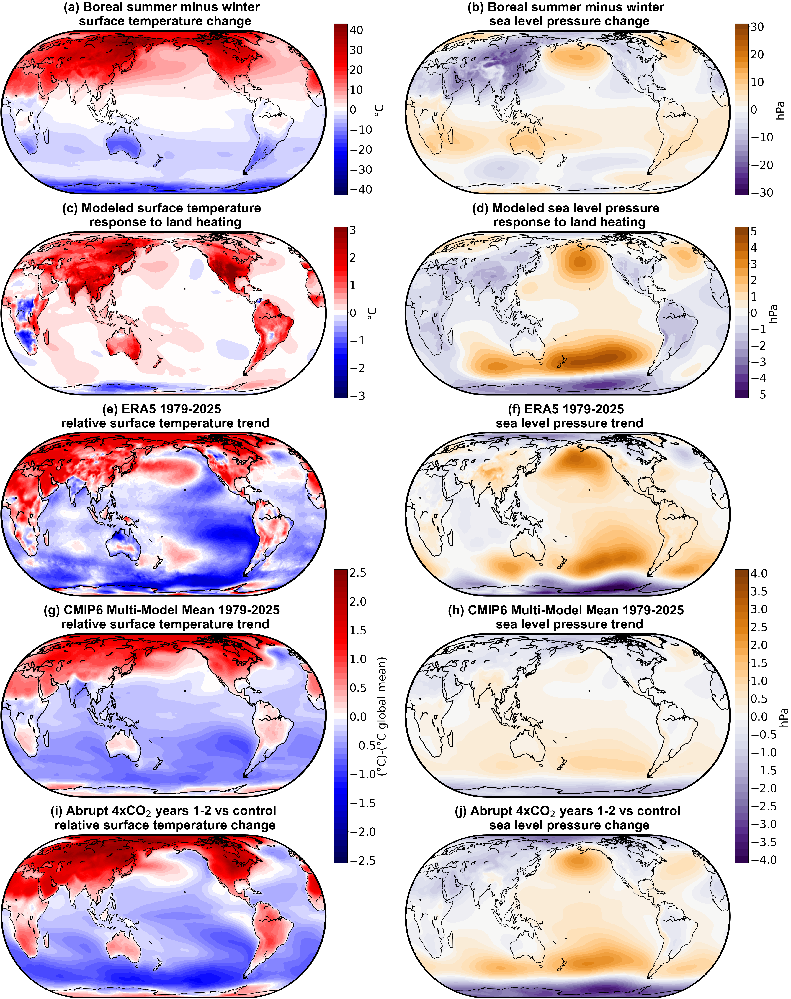

In [29]:
#Figure 1
Models = ['access_cm2','access_esm1_5','awi_cm_1_1_mr','bcc_csm2_mr','cams_csm1_0','canesm5',
          'canesm5_1','cas_esm2_0','cesm2','cesm2_fv2','cesm2_waccm','cmcc_cm2_sr5','cmcc_esm2',
          'cnrm_cm6_1_hr','cnrm_esm2_1','e3sm_1_0','ec_earth3_cc','ec_earth3_veg','ec_earth3_veg_lr',
          'fgoals_f3_l','fgoals_g3','fio_esm_2_0','gfdl_esm4','giss_e2_1_g','giss_e2_2_g',
          'hadgem3_gc31_ll','hadgem3_gc31_mm','iitm_esm','inm_cm4_8','inm_cm5_0','ipsl_cm6a_lr',
          'kace_1_0_g','kiost_esm','mcm_ua_1_0','miroc6','miroc_es2l','mpi_esm1_2_hr','mpi_esm1_2_lr',
          'mri_esm2_0','nesm3','noresm2_mm','taiesm1','ukesm1_0_ll']

Years = np.arange(1979,2026,1)
Months = [0,1,2,3,4,5,6,7,8,9,10,11]
T = GetERA5_TS('t2m',Months,Years)
Slopes_T,Pvals = GetRegression(T,Years)

#Seasonal cycle
Years_ERA5 = np.arange(1979,2026,1)
Months_S = [5,6,7,8]
Months_W = [0,1,2,11]
T_S = GetERA5_TS('t2m',Months_S,Years_ERA5)
SLP_S = GetERA5_TS('msl',Months_S,Years_ERA5)/100.
T_W = GetERA5_TS('t2m',Months_W,Years_ERA5)
SLP_W = GetERA5_TS('msl',Months_W,Years_ERA5)/100.
T_S,SLP_S,T_W,SLP_W = np.mean(T_S,axis=0),np.mean(SLP_S,axis=0),np.mean(T_W,axis=0),np.mean(SLP_W,axis=0)


Exp1 = 'ControlTopo'
Exp2 = 'LeafRef_High'
Months_SPEAR = ['01','02','03','04','05','06','07','08','09','10','11','12']
T1 = GetMonthMean_SPEAR(Exp1,'t_ref','SFC',Months_SPEAR)
T2 = GetMonthMean_SPEAR(Exp2,'t_ref','SFC',Months_SPEAR)
SLP1 = GetMonthMean_SPEAR(Exp1,'slp','SFC',Months_SPEAR)
SLP2 = GetMonthMean_SPEAR(Exp2,'slp','SFC',Months_SPEAR)
Alb1 = GetMonthMean_SPEAR(Exp1,'alb_sfc','SFC',Months_SPEAR)
Alb2 = GetMonthMean_SPEAR(Exp2,'alb_sfc','SFC',Months_SPEAR)




T = GetERA5_TS('t2m',Months,Years)
SLP = GetERA5_TS('msl',Months,Years)/100.
Slopes_T_ERA5,Pvals = GetRegression(T,Years)
Slopes_SLP_ERA5,Pvals = GetRegression(SLP,Years)


Years = np.arange(1979,2015,1)
T_2015 = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'t_ref',Years,Months,'SFC')
SLP_2015 = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'slp',Years,Months,'SFC')/100.


Years = np.arange(2015,2026,1)
T_2026 = GetCMIP6_100km_TS_MultiModelMean(Models,'t_ref',Years,Months,'SFC')
SLP_2026 = GetCMIP6_100km_TS_MultiModelMean(Models,'slp',Years,Months,'SFC')/100.
T_Full = np.concatenate((T_2015,T_2026))
SLP_Full = np.concatenate((SLP_2015,SLP_2026))
Years = np.arange(1979,2026,1)
Slopes_T_CMIP6,Pvals = GetRegression(T_Full,Years)
Slopes_SLP_CMIP6,Pvals = GetRegression(SLP_Full,Years)


T_CMIP6 = Slopes_T_CMIP6*len(Years)
T_CMIP6_Mean = GetGlobalMean_c96(T_CMIP6)
T_CMIP6_Anom = T_CMIP6-T_CMIP6_Mean
T_CMIP6_Anom[T_CMIP6_Anom > 1.55] = 1.55

Years = np.arange(1979,2026,1)
T_ERA5 = Slopes_T_ERA5*len(Years)
T_ERA5_Mean = GetGlobalMean_c96(T_ERA5)
T_ERA5_Anom = T_ERA5-T_ERA5_Mean
T_ERA5_Anom[T_ERA5_Anom > 1.55] = 1.55
T_ERA5_Anom[T_ERA5_Anom < -1.55] = -1.55


SLP_ERA5 = Slopes_SLP_ERA5*len(Years)
SLP_ERA5[SLP_ERA5<-4.05] = -4.05


Years = np.arange(0,2,1)
Years_Hist = np.arange(1900,1950,1)
SLP_MultiModel = Get4xCO2_MultiModelMean(Models,'slp',Months,Years,'SFC')/100.
SLP_MultiModel = np.mean(SLP_MultiModel,axis=0)
SLP_Hist_MultiModel = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'slp',Years_Hist,Months,'SFC')/100.
SLP_Hist_MultiModel = np.mean(SLP_Hist_MultiModel,axis=0)

T_MultiModel = Get4xCO2_MultiModelMean(Models,'t_ref',Months,Years,'SFC')
T_MultiModel = np.mean(T_MultiModel,axis=0)
T_Hist_MultiModel = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'t_ref',Years_Hist,Months,'SFC')
T_Hist_MultiModel = np.mean(T_Hist_MultiModel,axis=0)


Tchange = T_MultiModel-T_Hist_MultiModel
Tchange_Mean = GetGlobalMean_c96_LatBounds(Tchange,70)
Tchange_Anom = Tchange-Tchange_Mean
Tchange_Anom[Tchange_Anom>3.1] = 3.1






Months = [0,1,2,3,4,5,6,7,8,9,10,11]
import cmaps
fig = plt.figure(figsize=(49,66))
fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
ax = fig.add_subplot(5,2,1)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
T_Change = T_S-T_W
T_Change[T_Change>43] = 43
f = m.contourf(xx,yy,T_Change,cmap='seismic',levels=np.arange(-43,45,2))
plt.title('(a) Boreal summer minus winter \n surface temperature change',fontsize=50,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
cbar_ax = fig.add_axes([0.465, 0.761, 0.015, 0.14])
cbar = fig.colorbar(f,cax=cbar_ax,fraction=0.0005,orientation='vertical',extend='both')
cbar.ax.tick_params(labelsize=43)
cbar.set_label('°C',fontsize=43)
cbar.set_ticks([-40,-30,-20,-10,0,10,20,30,40])
[i.set_linewidth(4) for i in ax.spines.values()]

ax = fig.add_subplot(5,2,2)
m.drawcoastlines(linewidth=2)
f = m.contourf(xx,yy,SLP_S-SLP_W,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-31,33,2))
plt.title('(b) Boreal summer minus winter \n sea level pressure change',fontsize=50,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
cbar_ax = fig.add_axes([0.906, 0.761, 0.015, 0.14])
cbar = fig.colorbar(f,cax=cbar_ax,fraction=0.0005,orientation='vertical',extend='both')
cbar.ax.tick_params(labelsize=43)
cbar.set_label('hPa',fontsize=43)
cbar.set_ticks([-30,-20,-10,0,10,20,30])
[i.set_linewidth(10) for i in ax.spines.values()]

ax = fig.add_subplot(5,2,3)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c192,lats_c192)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
Tdiff = T1-T2
Tdiff[Tdiff>3.1]=3.1
f = m.contourf(xx,yy,Tdiff,cmap='seismic',levels=np.arange(-3.1,3.3,.2))
plt.title('(c) Modeled surface temperature \n response to land heating',fontsize=50,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
cbar_ax = fig.add_axes([0.465, 0.595, 0.015, 0.14])
cbar = fig.colorbar(f,cax=cbar_ax,fraction=0.0005,orientation='vertical',extend='both')
cbar.ax.tick_params(labelsize=43)
cbar.set_label('°C',fontsize=43)
cbar.set_ticks([-3,-2,-1,0,1,2,3])
[i.set_linewidth(4) for i in ax.spines.values()]


ax = fig.add_subplot(5,2,4)
m.drawcoastlines(linewidth=2)
f = m.contourf(xx,yy,SLP1-SLP2,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-5.25,5.75,.5))
plt.title('(d) Modeled sea level pressure \n response to land heating',fontsize=50,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
cbar_ax = fig.add_axes([0.906, 0.595, 0.015, 0.14])
cbar = fig.colorbar(f,cax=cbar_ax,fraction=0.0005,orientation='vertical',extend='both')
cbar.ax.tick_params(labelsize=43)
cbar.set_label('hPa',fontsize=43)
cbar.set_ticks([-5,-4,-3,-2,-1,0,1,2,3,4,5])
[i.set_linewidth(4) for i in ax.spines.values()]

ax = fig.add_subplot(5,2,7)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=3)
f = m.contourf(xx,yy,T_CMIP6_Anom,cmap='seismic',levels=np.arange(-2.55,2.65,.1))
plt.title('(g) CMIP6 Multi-Model Mean 1979-2025 \n relative surface temperature trend',fontsize=50,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
cbar_ax = fig.add_axes([0.465, 0.215, 0.015, 0.24])
cbar = fig.colorbar(f,cax=cbar_ax,fraction=0.0005,orientation='vertical',extend='both')
cbar.set_label('(°C)-(°C global mean)',fontsize=43)
cbar.ax.tick_params(labelsize=43)
cbar.set_ticks([-2.5,-2,-1.5,-1,-.5,0,.5,1,1.5,2,2.5])

ax = fig.add_subplot(5,2,8)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=3)
m.contourf(xx,yy,Slopes_SLP_CMIP6*45,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-4.1,4.3,.2))
plt.title('(h) CMIP6 Multi-Model Mean 1979-2025 \n sea level pressure trend',fontsize=50,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)

Years = np.arange(1979,2026,1)
T = GetERA5_TS('t2m',Months,Years)
SLP = GetERA5_TS('msl',Months,Years)/100.
Slopes_T_ERA5,Pvals = GetRegression(T,Years)
Slopes_SLP_ERA5,Pvals = GetRegression(SLP,Years)
T_ERA5 = Slopes_T_ERA5*len(Years)
T_ERA5_Mean = GetGlobalMean_c96(T_ERA5)
T_ERA5_Anom = T_ERA5-T_ERA5_Mean
T_ERA5_Anom[T_ERA5_Anom > 1.55] = 1.55
T_ERA5_Anom[T_ERA5_Anom < -1.55] = -1.55
ax = fig.add_subplot(5,2,5)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y) 
m.drawcoastlines(linewidth=3)
f = m.contourf(xx,yy,T_ERA5_Anom,cmap='seismic',levels=np.arange(-2.55,2.65,.1))
plt.title('(e) ERA5 1979-2025 \n relative surface temperature trend',fontsize=50,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)

ax = fig.add_subplot(5,2,6)
xx,yy = m(x,y)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=3)
f = m.contourf(xx,yy,SLP_ERA5,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-4.1,4.3,.2))
plt.title('(f) ERA5 1979-2025 \n sea level pressure trend',fontsize=50,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)


fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
ax = fig.add_subplot(5,2,9)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,Tchange_Anom,cmap='seismic',levels=np.arange(-2.55,2.65,.1))
plt.title('(i) Abrupt 4xCO$_2$ years 1-2 vs control \n relative surface temperature change',fontsize=50,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)


ax = fig.add_subplot(5,2,10)
m.drawcoastlines(linewidth=2)
f = m.contourf(xx,yy,SLP_MultiModel-SLP_Hist_MultiModel,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-4.1,4.3,.2))
plt.title('(j) Abrupt 4xCO$_2$ years 1-2 vs control \n sea level pressure change',fontsize=50,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
cbar_ax = fig.add_axes([0.906, 0.215, 0.015, 0.24])
cbar = fig.colorbar(f,cax=cbar_ax,fraction=0.0005,orientation='vertical',extend='both')
cbar.set_label('hPa',fontsize=43)
cbar.ax.tick_params(labelsize=43)
cbar.set_ticks([-4,-3.5,-3,-2.5,-2,-1.5,-1,-.5,0,.5,1,1.5,2,2.5,3,3.5,4])
plt.subplots_adjust(hspace=0.15, wspace=0.25)
plt.show() 


In [312]:
#Land-sea warming ratios
Models = ['access_cm2','access_esm1_5','awi_cm_1_1_mr','bcc_csm2_mr','cams_csm1_0','canesm5',
          'canesm5_1','cas_esm2_0','cesm2','cesm2_fv2','cesm2_waccm','cmcc_cm2_sr5','cmcc_esm2',
          'cnrm_cm6_1_hr','cnrm_esm2_1','e3sm_1_0','ec_earth3_cc','ec_earth3_veg','ec_earth3_veg_lr',
          'fgoals_f3_l','fgoals_g3','fio_esm_2_0','gfdl_esm4','giss_e2_1_g','giss_e2_2_g',
          'hadgem3_gc31_ll','hadgem3_gc31_mm','iitm_esm','inm_cm4_8','inm_cm5_0','ipsl_cm6a_lr',
          'kace_1_0_g','kiost_esm','mcm_ua_1_0','miroc6','miroc_es2l','mpi_esm1_2_hr','mpi_esm1_2_lr',
          'mri_esm2_0','nesm3','noresm2_mm','taiesm1','ukesm1_0_ll']


Years = np.arange(0,2,1)
Years_Hist = np.arange(1900,1950,1)

T_MultiModel = Get4xCO2_MultiModelMean(Models,'t_ref',Months,Years,'SFC')
T_MultiModel = np.mean(T_MultiModel,axis=0)
T_Hist_MultiModel = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'t_ref',Years_Hist,Months,'SFC')
T_Hist_MultiModel = np.mean(T_Hist_MultiModel,axis=0)

Tchange = T_MultiModel-T_Hist_MultiModel

Years = np.arange(1979,2026,1)
T_ERA5 = GetERA5_TS('t2m','SFC',Months,Years)
Slopes_T_ERA5,Pvals = GetRegression(T_ERA5,Years)

LatHigh = 70
LatInd_S = np.argmin(np.abs(lats_c96+LatHigh))
LatInd_N = np.argmin(np.abs(lats_c96-LatHigh-1))
LatHighNans = np.zeros_like(Slopes_T_CMIP6)
LatHighNans[:LatInd_S] = np.nan
LatHighNans[LatInd_N:] = np.nan


Years = np.arange(1979,2015,1)
T_2015_CMIP = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'t_ref',Years,Months,'SFC')
Years = np.arange(2015,2026,1)
T_2026_CMIP = GetCMIP6_100km_TS_MultiModelMean(Models,'t_ref',Years,Months,'SFC')
T_Full = np.concatenate((T_2015_CMIP,T_2026_CMIP))
Years = np.arange(1979,2026,1)
Slopes_T_CMIP,Pvals = GetRegression(T_Full,Years)

WarmingRatio_ERA5 = GetGlobalMean_c96_LandSea(Slopes_T_ERA5+LatHighNans+OceanNans)/GetGlobalMean_c96_LandSea(Slopes_T_ERA5+LatHighNans+LandNans)
WarmingRatio_4x = GetGlobalMean_c96_LandSea(Tchange+LatHighNans+OceanNans)/GetGlobalMean_c96_LandSea(Tchange+LatHighNans+LandNans)
WarmingRatio_CMIP = GetGlobalMean_c96_LandSea(Slopes_T_CMIP+LatHighNans+OceanNans)/GetGlobalMean_c96_LandSea(Slopes_T_CMIP+LatHighNans+LandNans)
print(WarmingRatio_CMIP)
print(WarmingRatio_ERA5)
print(WarmingRatio_4x)


LatHigh = 70
LatInd_S = np.argmin(np.abs(lats_c96+LatHigh))
LatInd_N = np.argmin(np.abs(lats_c96-LatHigh-1))
LatHighNans = np.zeros_like(Slopes_T_CMIP6)
LatHighNans[:LatInd_S] = np.nan
LatHighNans[LatInd_N:] = np.nan



Lands = []
Oceans = []
Ratios = []
for Model in Models:
    Months = [0,1,2,3,4,5,6,7,8,9,10,11]
    Years = np.arange(1979,2015,1)
    T_2015 = GetCMIP6_100km_Historical_TS_MultiModelMean([Model],'t_ref',Years,Months,'SFC')
    Years = np.arange(2015,2026,1)
    T_2026 = GetCMIP6_100km_TS_MultiModelMean([Model],'t_ref',Years,Months,'SFC')
    T_Full = np.concatenate((T_2015,T_2026))
    Years = np.arange(1979,2026,1)
    Slopes_T_CMIP6,Pvals = GetRegression(T_Full,Years)
    Land = GetGlobalMean_c96_LandSea(Slopes_T_CMIP6+LatHighNans+OceanNans)*len(Years)
    Ocean = GetGlobalMean_c96_LandSea(Slopes_T_CMIP6+LatHighNans+LandNans)*len(Years)
    Ratio = Land/Ocean
    Global = GetGlobalMean_c96_LandSea(Slopes_T_CMIP6)*len(Years)
    Lands.append(Land)
    Oceans.append(Ocean)
    Ratios.append(Ratio)
print(np.min(Lands),np.max(Lands))
print(np.min(Oceans),np.max(Oceans))
print(np.min(Ratios),np.max(Ratios))


1.7828500885793017
2.3711458089413813
2.4358240855061144
0.8743206942375669 2.586532570049071
0.6042388517304517 1.5271583156856028
1.3377715288084775 2.231553679395201


(36, 72)
(36, 72)
159
19


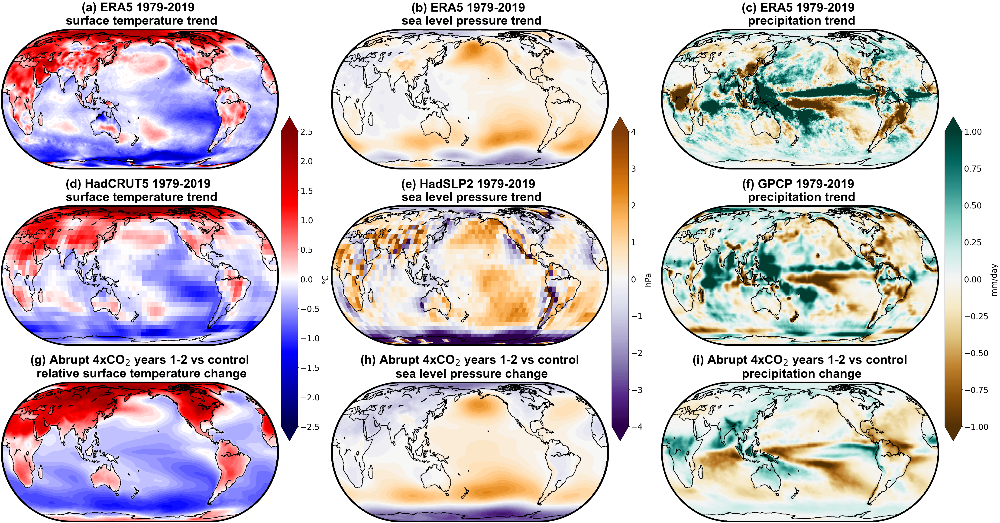

In [313]:
#Figure 2
Months = [0,1,2,3,4,5,6,7,8,9,10,11]
Years = np.arange(1979,2020,1)



DataArray = read_hadslp_ascii('/Users/benjaminjohnson/Downloads/hadslp2r.asc')
YearMeans = np.zeros((2020-1979,36,72)) 
n=0
for Year in range(1979-1850,2020-1850):
    YearStart,YearEnd = Year*12,Year*12+12
    YearData = DataArray[YearStart:YearEnd]
    
    YearMean = np.mean(YearData,axis=0)/100.
    YearMeans[n] = YearMean
    n+=1
Hadley_SLP_TS = YearMeans
Hadley_SLP_TS = np.flipud(YearMeans)
lats_Hadley = np.linspace(-90,90,36)
lons_Hadley = np.linspace(-180,180,72)

Slopes_SLP_Hadley,Pvals = GetRegression(Hadley_SLP_TS,Years)
SLP_ERA5 = GetERA5_TS('msl','SFC',Months,Years)/100.
Slopes_SLP_ERA5,Pvals = GetRegression(SLP_ERA5,Years)

Slopes_SLP_Hadley_Trans = TransformHadley(Slopes_SLP_Hadley)
lons_Hadley_Trans = np.linspace(0,360,72)

YearMeans = np.zeros((2020-1979,36,72)) 
n=0
for Year in range(1979-1850,2020-1850):
    YearStart,YearEnd = Year*12,Year*12+12
    YearData = DataArray[YearStart:YearEnd]
    
    YearMean = np.mean(YearData,axis=0)/100.
    YearMeans[n] = YearMean
    n+=1
    
Hadley_SLP_TS = YearMeans
Slopes,Pvals = GetRegression(YearMeans,np.arange(1979,2020,1))
Slopes = np.flipud(Slopes)

lats = np.linspace(-90,90,36)
lons = np.linspace(-180,180,72)

P_ERA5 = 1000*GetERA5_TS('tp','SFC',Months,Years)
P_GPCP = GetGPCP_TS(Months,Years)
Slopes_P_ERA5,Pvals = GetRegression(P_ERA5,Years)
Slopes_P_GPCP,Pvals = GetRegression(P_GPCP,Years)

lons_Hadley_Wrapped = np.zeros(len(lons_Hadley)-1)
lons_Hadley_Wrapped[:36] = lons_Hadley[36:]
lons_Hadley_Wrapped[36:] = lons_Hadley[1:36]+360
Slopes_Wrapped = np.zeros((len(lats_Hadley),len(lons_Hadley_Wrapped)))
Slopes_Wrapped[:,:36] = Slopes[:,36:]
Slopes_Wrapped[:,36:] = Slopes[:,1:36]



Data_Hadcrut = netCDF4.Dataset('/Users/benjaminjohnson/Desktop/Postdoc Research/Data/Hadcrut/HadCRUT.5.1.0.0.analysis.anomalies.ensemble_mean.nc')
lats_Hadcrut,lons_Hadcrut = Data_Hadcrut.variables['latitude'][:],Data_Hadcrut.variables['longitude'][:]

Index_1979 = (1979-1850)*12

Months = [0,1,2,3,4,5,6,7,8,9,10,11]
Years = np.arange(1979,2020,1)
TS_Hadcrut = GetHadcrut(Months,Years)
Slopes_Hadcrut,Pvals = GetRegression(TS_Hadcrut,Years)
Slopes_Hadcrut_Wrapped = np.zeros((len(lats_Hadcrut),len(lons_Hadcrut)-1))
lons_Hadcrut_Wrapped = np.zeros(len(lons_Hadcrut)-1)
lons_Hadcrut_Wrapped[:36] = lons_Hadcrut[36:]
lons_Hadcrut_Wrapped[36:] = lons_Hadcrut[1:36]+360
Slopes_Hadcrut_Wrapped[:,:36] = Slopes_Hadcrut[:,36:]
Slopes_Hadcrut_Wrapped[:,36:] = Slopes_Hadcrut[:,1:36]

Models = ['access_cm2','access_esm1_5','awi_cm_1_1_mr','bcc_csm2_mr','cams_csm1_0','canesm5',
          'canesm5_1','cas_esm2_0','cesm2','cesm2_fv2','cesm2_waccm','cmcc_cm2_sr5','cmcc_esm2',
          'cnrm_cm6_1_hr','cnrm_esm2_1','e3sm_1_0','ec_earth3_cc','ec_earth3_veg','ec_earth3_veg_lr',
          'fgoals_f3_l','fgoals_g3','fio_esm_2_0','gfdl_esm4','giss_e2_1_g','giss_e2_2_g',
          'hadgem3_gc31_ll','hadgem3_gc31_mm','iitm_esm','inm_cm4_8','inm_cm5_0','ipsl_cm6a_lr',
          'kace_1_0_g','kiost_esm','mcm_ua_1_0','miroc6','miroc_es2l','mpi_esm1_2_hr','mpi_esm1_2_lr',
          'mri_esm2_0','nesm3','noresm2_mm','taiesm1','ukesm1_0_ll']

Mean_Hadcrut = area_weighted_mean(lats_Hadcrut,lons_Hadcrut_Wrapped,Slopes_Hadcrut_Wrapped)
GPCP = GetGPCP_TS(Months,Years)
Slopes_GPCP,Pvals = GetRegression(GPCP,Years)
T_ERA5 = GetERA5_TS('t2m','SFC',Months,Years)
SLP_ERA5 = GetERA5_TS('msl','SFC',Months,Years)/100.
P_ERA5 = 1000*GetERA5_TS('tp','SFC',Months,Years)
Slopes_T_ERA5,Pvals = GetRegression(T_ERA5,Years)
Slopes_SLP_ERA5,Pvals = GetRegression(SLP_ERA5,Years)
Slopes_P_ERA5,Pvals = GetRegression(P_ERA5,Years)
Slopes_T_ERA5_Mean = area_weighted_mean(lats_c96,lons_c96,Slopes_T_ERA5)


Years = np.arange(0,2,1)
Years_Hist = np.arange(1900,1950,1)
SLP_MultiModel = Get4xCO2_MultiModelMean(Models,'slp',Months,Years,'SFC')/100.
SLP_MultiModel = np.mean(SLP_MultiModel,axis=0)
SLP_Hist_MultiModel = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'slp',Years_Hist,Months,'SFC')/100.
SLP_Hist_MultiModel = np.mean(SLP_Hist_MultiModel,axis=0)
SLPchange = SLP_MultiModel-SLP_Hist_MultiModel

T_MultiModel = Get4xCO2_MultiModelMean(Models,'t_ref',Months,Years,'SFC')
T_MultiModel = np.mean(T_MultiModel,axis=0)
T_Hist_MultiModel = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'t_ref',Years_Hist,Months,'SFC')
T_Hist_MultiModel = np.mean(T_Hist_MultiModel,axis=0)

P_MultiModel = 86400*Get4xCO2_MultiModelMean(Models,'precip',Months,Years,'SFC')
P_MultiModel = np.mean(P_MultiModel,axis=0)
P_Hist_MultiModel = 86400*GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'precipitation',Years_Hist,Months,'SFC')
P_Hist_MultiModel = np.mean(P_Hist_MultiModel,axis=0)
Pchange = P_MultiModel-P_Hist_MultiModel



Tchange = T_MultiModel-T_Hist_MultiModel
Tchange_Mean = GetGlobalMean_c96_LatBounds(Tchange,70)
Tchange_Anom = Tchange-Tchange_Mean
Tchange_Anom[Tchange_Anom>2.5] = 2.5


Years = np.arange(1979,2020,1)
fig = plt.figure(figsize=(52,28))
ax = fig.add_subplot(3,3,1)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
Tchange_ERA5 = (Slopes_T_ERA5-Slopes_T_ERA5_Mean)*len(Years)
Tchange_ERA5[Tchange_ERA5>2] = 2
f = m.contourf(xx,yy,Tchange_ERA5,cmap='seismic',levels=np.arange(-2.55,2.65,.1))
plt.title('(a) ERA5 1979-2019 \n surface temperature trend',fontsize=38,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(7) for i in ax.spines.values()]

ax = fig.add_subplot(3,3,2)
m.drawcoastlines(linewidth=2)
f = m.contourf(xx,yy,Slopes_SLP_ERA5*len(Years),cmap=cmaps.MPL_PuOr_r,levels=np.arange(-4.1,4.3,.2))
plt.title('(b) ERA5 1979-2019 \n sea level pressure trend',fontsize=38,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(7) for i in ax.spines.values()]

ax = fig.add_subplot(3,3,3)
m.drawcoastlines(linewidth=2)
f = m.pcolormesh(xx,yy,Slopes_P_ERA5*len(Years),cmap='BrBG',vmin=-1,vmax=1)
plt.title('(c) ERA5 1979-2019 \n precipitation trend',fontsize=38,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(7) for i in ax.spines.values()]


ax = fig.add_subplot(3,3,4)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_Hadcrut_Wrapped,lats_Hadcrut)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
f_T = m.pcolormesh(xx,yy,(Slopes_Hadcrut_Wrapped-Mean_Hadcrut)*len(Years),cmap='seismic',vmin=-2.5,vmax=2.5)
plt.title('(d) HadCRUT5 1979-2019 \n surface temperature trend',fontsize=38,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(7) for i in ax.spines.values()]

ax = fig.add_subplot(3,3,5)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_Hadley_Wrapped,lats)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
f_SLP = m.pcolormesh(xx,yy,Slopes_Wrapped*len(Years),cmap=cmaps.MPL_PuOr_r,vmin=-4,vmax=4)
plt.title('(e) HadSLP2 1979-2019 \n sea level pressure trend',fontsize=38,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(7) for i in ax.spines.values()]


ax = fig.add_subplot(3,3,6)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
f = m.pcolormesh(xx,yy,Slopes_GPCP*len(Years),cmap='BrBG',vmin=-1,vmax=1)
plt.title('(f) GPCP 1979-2019 \n precipitation trend',fontsize=38,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(7) for i in ax.spines.values()]



ax = fig.add_subplot(3,3,7)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
f = m.contourf(xx,yy,Tchange_Anom,cmap='seismic',levels=np.arange(-2.55,2.65,.1))
plt.title('(g) Abrupt 4xCO$_2$ years 1-2 vs control \n relative surface temperature change',fontsize=38,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(7) for i in ax.spines.values()]
cbar_ax = fig.add_axes([0.356, 0.24, 0.014, 0.5])
cbar = fig.colorbar(f_T,cax=cbar_ax,fraction=0.0005,orientation='vertical',extend='both')
cbar.set_label('°C',fontsize=25)
cbar.ax.tick_params(labelsize=25)
cbar.set_ticks([-2.5,-2,-1.5,-1,-.5,0,.5,1,1.5,2,2.5])


SLPchange[SLPchange<-4.1] = -4.1
ax = fig.add_subplot(3,3,8)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
f = m.contourf(xx,yy,SLPchange,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-4.1,4.3,.2))
plt.title('(h) Abrupt 4xCO$_2$ years 1-2 vs control \n sea level pressure change',fontsize=38,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(7) for i in ax.spines.values()]

cbar_ax = fig.add_axes([0.63, 0.24, 0.014, 0.5])
cbar = fig.colorbar(f_SLP,cax=cbar_ax,fraction=0.0005,orientation='vertical',extend='both')
cbar.set_label('hPa',fontsize=25)
cbar.ax.tick_params(labelsize=25)
cbar.set_ticks([-4,-3,-2,-1,0,1,2,3,4])


ax = fig.add_subplot(3,3,9)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
f = m.pcolormesh(xx,yy,Pchange,cmap='BrBG',vmin=-1,vmax=1)
plt.title('(i) Abrupt 4xCO$_2$ years 1-2 vs control \n precipitation change',fontsize=38,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(7) for i in ax.spines.values()]

cbar_ax = fig.add_axes([0.906, 0.24, 0.014, 0.5])
cbar = fig.colorbar(f,cax=cbar_ax,fraction=0.0005,orientation='vertical',extend='both')
cbar.set_label('mm/day',fontsize=25)
cbar.ax.tick_params(labelsize=25)
cbar.set_ticks([-1,-.75,-.5,-.25,0,.25,.5,.75,1])
plt.savefig('/Users/benjaminjohnson/Desktop/ObservationUncertainty.png')




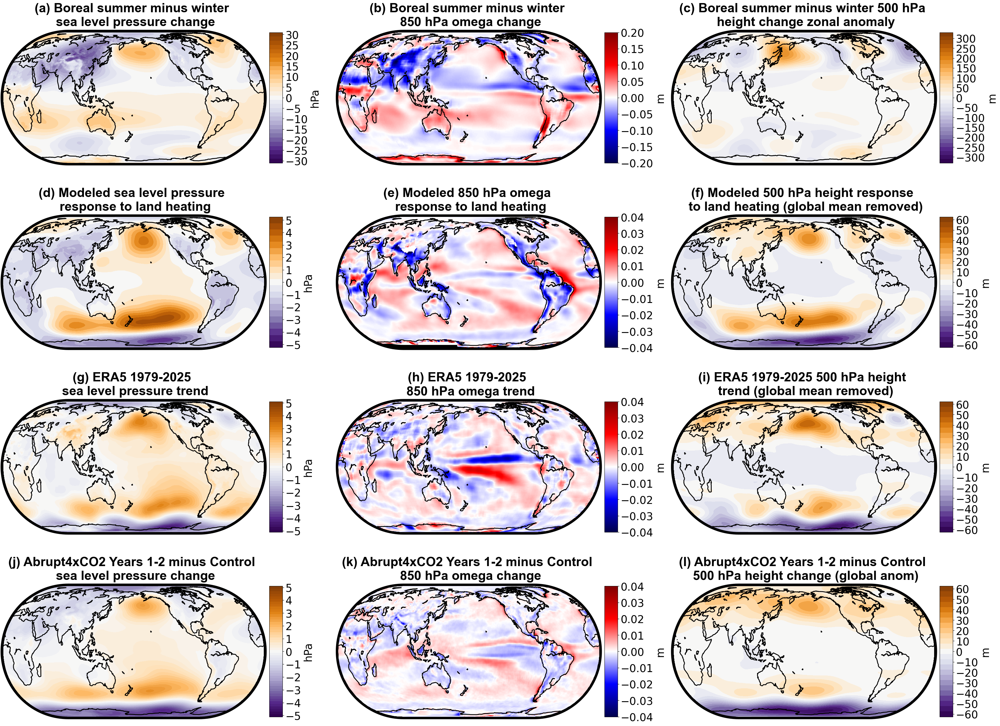

In [317]:
#Figure S1

#Seasonal cycle
Years_ERA5 = np.arange(1979,2026,1)
Months_S = [5,6,7,8]
Months_W = [0,1,2,11]
SLP_S = GetERA5_TS('msl','SFC',Months_S,Years_ERA5)/100.
SLP_W = GetERA5_TS('msl','SFC',Months_W,Years_ERA5)/100.
Z500_S = GetERA5_TS('z500','500',Months_S,Years_ERA5)/9.806
Z500_W = GetERA5_TS('z500','500',Months_W,Years_ERA5)/9.806
SLP_S,SLP_W,Z500_S,Z500_W = np.mean(SLP_S,axis=0),np.mean(SLP_W,axis=0),np.mean(Z500_S,axis=0),np.mean(Z500_W,axis=0)

Months = [0,1,2,3,4,5,6,7,8,9,10,11]


T = GetERA5_TS('t2m','SFC',Months,Years_ERA5)
SLP = GetERA5_TS('msl','SFC',Months,Years_ERA5)/100.
Z = GetERA5_TS('z500','500',Months,Years_ERA5)/9.806
Slopes_T,Pvals = GetRegression(T,Years_ERA5)
Slopes_SLP,Pvals = GetRegression(SLP,Years_ERA5)
Slopes_Z,Pvals = GetRegression(Z,Years_ERA5)

Months_SPEAR = ['01','02','03','04','05','06','07','08','09','10','11','12']
Exp1 = 'ControlTopo'
Exp2 = 'LeafRef_High'


Lev = 500
Z1 = GetMonthMean_SPEAR(Exp1,'hght',Lev,Months_SPEAR)
Z2 = GetMonthMean_SPEAR(Exp2,'hght',Lev,Months_SPEAR)
SLP1 = GetMonthMean_SPEAR(Exp1,'slp','SFC',Months_SPEAR)
SLP2 = GetMonthMean_SPEAR(Exp2,'slp','SFC',Months_SPEAR)
Zchange = Z1-Z2


W_S = GetERA5_TS('w850','850',Months_S,Years_ERA5)
W_W = GetERA5_TS('w850','850',Months_W,Years_ERA5)
W_S = TS_SpatialSmoothing(W_S,3)
W_W = TS_SpatialSmoothing(W_W,3)
W_S = np.mean(W_S,axis=0)
W_W = np.mean(W_W,axis=0)

W1 = GetMonthMean_SPEAR(Exp1,'omega',850,Months_SPEAR)
W2 = GetMonthMean_SPEAR(Exp2,'omega',850,Months_SPEAR)
W1 = TS_SpatialSmoothing_2D(W1,4)
W2 = TS_SpatialSmoothing_2D(W2,4)

W = GetERA5_TS('w850','850',Months,Years_ERA5)
W = TS_SpatialSmoothing(W,3)
Slopes_W,Pvals = GetRegression(W,Years_ERA5)

Models = ['taiesm1','awi_cm_1_1_mr','bcc_csm2_mr','cams_csm1_0','canesm5','access_cm2','e3sm_1_0',
         'fio_esm_2_0','kiost_esm','miroc6','mpi_esm1_2_hr','mri_esm2_0','giss_e2_1_g','noresm2_mm',
         'gfdl_esm4','fgoals_f3_l','kace_1_0_g','nesm3','cesm2','hadgem3_gc31_ll']


Years = np.arange(1900,1950,1)
Months = [0,1,2,3,4,5,6,7,8,9,10,11]
w850_Hist = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'wap',Years,Months,'850')
z500_Hist = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'zg',Years,Months,'500')
SLP_Hist = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'slp',Years,Months,'SFC')/100.
Years = np.arange(0,2,1)
w850_4xCO2 = Get4xCO2_MultiModelMean(Models,'wap',Months,Years,'850')
z500_4xCO2 = Get4xCO2_MultiModelMean(Models,'zg',Months,Years,'500')
SLP_4xCO2 = Get4xCO2_MultiModelMean(Models,'slp',Months,Years,'SFC')/100.
w850_diff = np.mean(w850_4xCO2,axis=0)-np.mean(w850_Hist,axis=0)
z500_diff = np.mean(z500_4xCO2,axis=0)-np.mean(z500_Hist,axis=0)
SLP_diff = np.mean(SLP_4xCO2,axis=0)-np.mean(SLP_Hist,axis=0)
z500_diff_anom = z500_diff - GetGlobalMean_c96(z500_diff)



import cmaps

fig = plt.figure(figsize=(40,30))
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
ax = fig.add_subplot(4,3,1)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,SLP_S-SLP_W,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-31,33,2))
plt.title('(a) Boreal summer minus winter \n sea level pressure change',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('hPa',fontsize=25)
cbar.set_ticks([-30,-25,-20,-15,-10,-5,0,5,10,15,20,25,30])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]
Slopes_Z_Anom = Slopes_Z-GetGlobalMean_c96(Slopes_Z)


ax = fig.add_subplot(4,3,2)
m.drawcoastlines(linewidth=2)
m.pcolormesh(xx,yy,W_S-W_W,cmap='seismic',vmin=-.2,vmax=.2)
plt.title('(b) Boreal summer minus winter \n 850 hPa omega change',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('m',fontsize=25)
cbar.set_ticks([-.2,-.15,-.1,-.05,0,.05,.1,.15,.2])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]




Zchange_WS = Z500_S-Z500_W
Zchange_WS_Anom = np.zeros_like(Zchange_WS)
for lat in range(len(lats_c96)):
    Zchange_latMean = np.mean(Zchange_WS[lat])
    Zchange_WS_Anom[lat] = Zchange_WS[lat]-Zchange_latMean
    
ax = fig.add_subplot(4,3,3)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,Zchange_WS_Anom,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-330,350,20))
plt.title('(c) Boreal summer minus winter 500 hPa \n height change zonal anomaly',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('m',fontsize=25)
cbar.set_ticks([-300,-250,-200,-150,-100,-50,0,50,100,150,200,250,300])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]





ax = fig.add_subplot(4,3,4)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c192,lats_c192)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,SLP1-SLP2,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-5.25,5.75,.5))
plt.title('(d) Modeled sea level pressure \n response to land heating',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('hPa',fontsize=25)
cbar.set_ticks([-5,-4,-3,-2,-1,0,1,2,3,4,5])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]

ax = fig.add_subplot(4,3,5)
m.drawcoastlines(linewidth=2)
m.pcolormesh(xx,yy,W1-W2,cmap='seismic',vmin=-.04,vmax=.04)
plt.title('(e) Modeled 850 hPa omega \n response to land heating',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('m',fontsize=25)
cbar.set_ticks([-.04,-.03,-.02,-.01,0,.01,.02,.03,.04])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]




skip = (slice(None,None,12),slice(None,None,12))
ax = fig.add_subplot(4,3,6)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,Zchange-10,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-62.5,67.5,5))
plt.title('(f) Modeled 500 hPa height response \n to land heating (global mean removed)',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('m',fontsize=25)
cbar.set_ticks([-60,-50,-40,-30,-20,-10,0,10,20,30,40,50,60])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]


Years = np.arange(1979,2026,1)
ax = fig.add_subplot(4,3,7)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,Slopes_SLP*len(Years_ERA5),cmap=cmaps.MPL_PuOr_r,levels=np.arange(-5.1,5.3,.2))
plt.title('(g) ERA5 1979-2025 \n sea level pressure trend',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('hPa',fontsize=25)
cbar.set_ticks([-5,-4,-3,-2,-1,0,1,2,3,4,5])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]
Slopes_Z_Anom = Slopes_Z-GetGlobalMean_c96(Slopes_Z)

ax = fig.add_subplot(4,3,8)
m.drawcoastlines(linewidth=2)
m.pcolormesh(xx,yy,Slopes_W*len(Years),cmap='seismic',vmin=-.04,vmax=.04)
plt.title('(h) ERA5 1979-2025 \n 850 hPa omega trend',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('m',fontsize=25)
cbar.set_ticks([-.04,-.03,-.02,-.01,0,.01,.02,.03,.04])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]

ax = fig.add_subplot(4,3,9)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,Slopes_Z_Anom*len(Years_ERA5),cmap=cmaps.MPL_PuOr_r,levels=np.arange(-62.5,67.5,5))
plt.title('(i) ERA5 1979-2025 500 hPa height \n trend (global mean removed)',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('m',fontsize=25)
cbar.set_ticks([-60,-50,-40,-30,-20,-10,0,10,20,30,40,50,60])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]





ax = fig.add_subplot(4,3,10)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,SLP_diff,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-5.1,5.3,.2))
plt.title('(j) Abrupt4xCO2 Years 1-2 minus Control \n sea level pressure change',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('hPa',fontsize=25)
cbar.set_ticks([-5,-4,-3,-2,-1,0,1,2,3,4,5])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]
Slopes_Z_Anom = Slopes_Z-GetGlobalMean_c96(Slopes_Z)

ax = fig.add_subplot(4,3,11)
m.drawcoastlines(linewidth=2)
m.pcolormesh(xx,yy,w850_diff,cmap='seismic',vmin=-.04,vmax=.04)
plt.title('(k) Abrupt4xCO2 Years 1-2 minus Control \n 850 hPa omega change',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('m',fontsize=25)
cbar.set_ticks([-.04,-.03,-.02,-.01,0,.01,.02,.03,.04])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]

ax = fig.add_subplot(4,3,12)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,z500_diff_anom,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-62.5,67.5,5))
plt.title('(l) Abrupt4xCO2 Years 1-2 minus Control \n 500 hPa height change (global anom)',fontsize=30,fontweight='bold',fontname="Arial",y=1.03)
cbar = m.colorbar()
cbar.ax.tick_params(labelsize=25)
cbar.set_label('m',fontsize=25)
cbar.set_ticks([-60,-50,-40,-30,-20,-10,0,10,20,30,40,50,60])
boundary = m.drawmapboundary(linewidth=12, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]
plt.show()



access_cm2
access_esm1_5
awi_cm_1_1_mr
bcc_csm2_mr
cams_csm1_0
canesm5
canesm5_1
cas_esm2_0
cesm2
cesm2_fv2
cesm2_waccm
cmcc_cm2_sr5
cmcc_esm2
cnrm_cm6_1_hr
cnrm_esm2_1
e3sm_1_0
ec_earth3_cc
ec_earth3_veg
ec_earth3_veg_lr
fgoals_f3_l
fgoals_g3
fio_esm_2_0
gfdl_esm4
giss_e2_1_g
giss_e2_2_g
hadgem3_gc31_ll
hadgem3_gc31_mm
iitm_esm
inm_cm4_8
inm_cm5_0
ipsl_cm6a_lr
kace_1_0_g
kiost_esm
mcm_ua_1_0
miroc6
miroc_es2l
mpi_esm1_2_hr
mpi_esm1_2_lr
mri_esm2_0
nesm3
noresm2_mm
taiesm1
ukesm1_0_ll


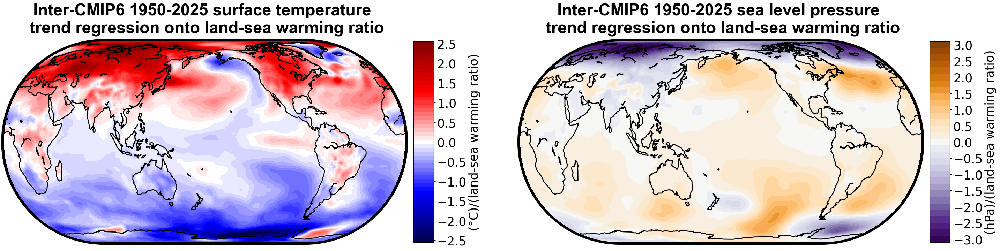

In [323]:
#Figure S2

Models = ['access_cm2','access_esm1_5','awi_cm_1_1_mr','bcc_csm2_mr','cams_csm1_0','canesm5',
          'canesm5_1','cas_esm2_0','cesm2','cesm2_fv2','cesm2_waccm','cmcc_cm2_sr5','cmcc_esm2',
          'cnrm_cm6_1_hr','cnrm_esm2_1','e3sm_1_0','ec_earth3_cc','ec_earth3_veg','ec_earth3_veg_lr',
          'fgoals_f3_l','fgoals_g3','fio_esm_2_0','gfdl_esm4','giss_e2_1_g','giss_e2_2_g',
          'hadgem3_gc31_ll','hadgem3_gc31_mm','iitm_esm','inm_cm4_8','inm_cm5_0','ipsl_cm6a_lr',
          'kace_1_0_g','kiost_esm','mcm_ua_1_0','miroc6','miroc_es2l','mpi_esm1_2_hr','mpi_esm1_2_lr',
          'mri_esm2_0','nesm3','noresm2_mm','taiesm1','ukesm1_0_ll']

LatHigh = 70
LatLow = -70
LatInd_S = np.argmin(np.abs(lats_c96-LatLow))
LatInd_N = np.argmin(np.abs(lats_c96-LatHigh-1))
LatHighNans = np.zeros((len(lats_c96),len(lons_c96)))
LatHighNans[:LatInd_S] = np.nan
LatHighNans[LatInd_N:] = np.nan


Region = np.zeros((len(lats_c96),len(lons_c96)))
Region = Region + LatHighNans

#Inter-CMIP6 regression


Slopes_T_Models = np.zeros((len(Models),len(lats_c96),len(lons_c96)))
Slopes_SLP_Models = np.zeros((len(Models),len(lats_c96),len(lons_c96)))
Slopes_P_Models = np.zeros((len(Models),len(lats_c96),len(lons_c96)))
WarmingRatios = []



n=0
for Model in Models:
    print(Model)
    Years = np.arange(1979,2015,1)
    T_2015 = GetCMIP6_100km_Historical_TS_MultiModelMean([Model],'t_ref',Years,Months,'SFC')
    SLP_2015 = GetCMIP6_100km_Historical_TS_MultiModelMean([Model],'slp',Years,Months,'SFC')/100.
    

    Years = np.arange(2015,2026,1)
    T_2024 = GetCMIP6_100km_TS_MultiModelMean([Model],'t_ref',Years,Months,'SFC')
    SLP_2024 = GetCMIP6_100km_TS_MultiModelMean([Model],'slp',Years,Months,'SFC')/100.
    T_Full = np.concatenate((T_2015,T_2024))
    SLP_Full = np.concatenate((SLP_2015,SLP_2024))
    Years = np.arange(1979,2026,1)
    Slopes_T_CMIP6,Pvals = GetRegression(T_Full,Years)
    Slopes_SLP_CMIP6,Pvals = GetRegression(SLP_Full,Years)
    Slopes_T_CMIP6 = Slopes_T_CMIP6
    Slopes_SLP_CMIP6 = Slopes_SLP_CMIP6

    Warming_Global = GetGlobalMean_c96(Slopes_T_CMIP6)
    Slopes_T_Models[n] = Slopes_T_CMIP6/Warming_Global
    Slopes_SLP_Models[n] = Slopes_SLP_CMIP6/Warming_Global

    #Slopes_T_Models[n] = Slopes_T_CMIP6
    #Slopes_SLP_Models[n] = Slopes_SLP_CMIP6
    
    WarmingRatio = GetGlobalMean_c96_LandSea(Slopes_T_CMIP6+Region+OceanNans)/GetGlobalMean_c96_LandSea(Slopes_T_CMIP6+Region+LandNans)
    WarmingRatios.append(WarmingRatio)
    n+=1

Slopes_T,Pvals_T = GetRegression(Slopes_T_Models,WarmingRatios)
Slopes_SLP,Pvals_SLP = GetRegression(Slopes_SLP_Models,WarmingRatios)


GlobalMean = GetGlobalMean_c96(Slopes_T)

import cmaps
fig = plt.figure(figsize=(35,20))
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
ax = fig.add_subplot(2,2,1)
m.drawcoastlines(linewidth=2)
Slopes_T[Slopes_T>2.55] = 2.55
Slopes_T[Slopes_T<-2.55] = -2.55
m.contourf(xx,yy,Slopes_T,cmap='seismic',levels=np.arange(-2.55,2.65,.1))
plt.title('Inter-CMIP6 1950-2025 surface temperature \n trend regression onto land-sea warming ratio',fontsize=34,y=1.03,fontweight='bold',fontname="Arial")
cbar = m.colorbar()
cbar.set_label('(°C)/(land-sea warming ratio)',fontsize=25)
cbar.set_ticks([-2.5,-2,-1.5,-1,-.5,0,.5,1,1.5,2,2.5])
cbar.ax.tick_params(labelsize=25)
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)

Slopes_SLP[Slopes_SLP<-3.1]=-3.1
import cmaps
ax = fig.add_subplot(2,2,2)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,Slopes_SLP,cmap=cmaps.MPL_PuOr_r,levels=np.arange(-3.1,3.3,.2))
plt.title('Inter-CMIP6 1950-2025 sea level pressure \n trend regression onto land-sea warming ratio',fontsize=34,y=1.03,fontweight='bold',fontname="Arial")
cbar = m.colorbar()
cbar.set_label('(hPa)/(land-sea warming ratio)',fontsize=25)
cbar.set_ticks([-3,-2.5,-2,-1.5,-1,-.5,0,.5,1,1.5,2,2.5,3])
cbar.ax.tick_params(labelsize=25)
boundary = m.drawmapboundary(linewidth=10, color='black')
boundary.set_clip_on(False)
plt.savefig('/Users/benjaminjohnson/Desktop/CMIP6_TrendRegression.png')
plt.show() 


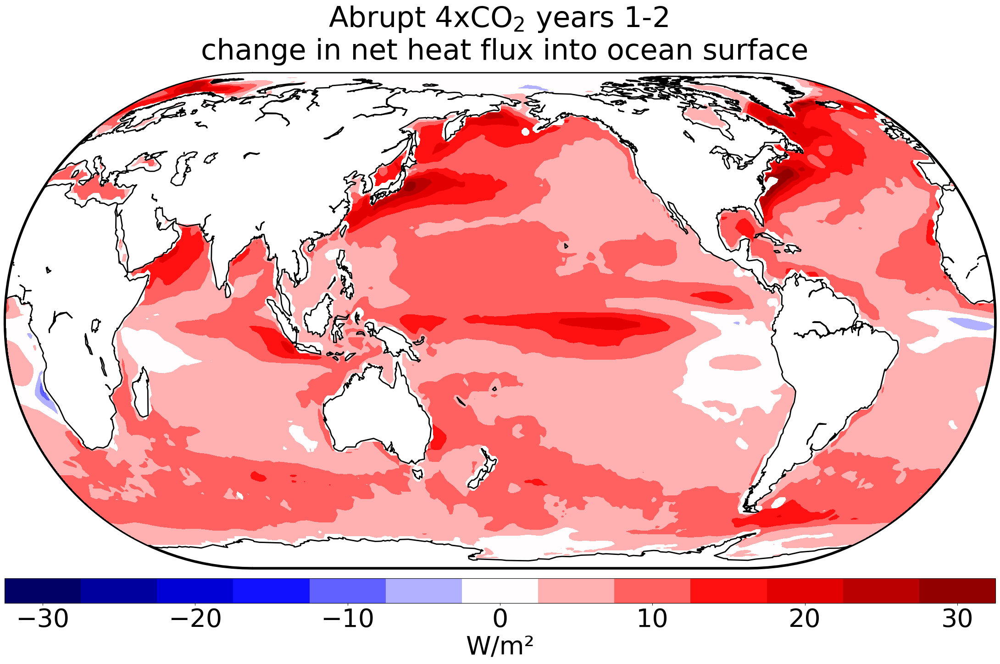

In [325]:
#Figure S3
Models = ['access_cm2','access_esm1_5','cams_csm1_0','canesm5','canesm5_1','cas_esm2_0','cesm2','cesm2_fv2',
          'cesm2_waccm','cmcc_cm2_hr4','cmcc_cm2_sr5','cmcc_esm2','cnrm_cm6_1_hr','cnrm_esm2_1','e3sm_1_0',
          'e3sm_1_0','ec_earth3_cc','ec_earth3_veg','ec_earth3_veg_lr','fgoals_f3_l','fgoals_g3','fio_esm_2_0','gfdl_esm4',
          'giss_e2_1_g','giss_e2_2_g','hadgem3_gc31_ll','hadgem3_gc31_mm','ipsl_cm6a_lr','kiost_esm','mcm_ua_1_0',
          'mpi_esm1_2_hr','mpi_esm1_2_lr','mri_esm2_0','nesm3','norcpm1','noresm2_mm','taiesm1','ukesm1_0_ll'] #Models with hfds available
Years = np.arange(0,2,1)
hfds = np.mean(Get4xCO2_MultiModelMean(Models,'hfds',Months,Years,'SFC'),axis=0)
T = np.mean(Get4xCO2_MultiModelMean(Models,'t_ref',Months,Years,'SFC'),axis=0)



Years_Hist = np.arange(1900,1950,1) 

hfds_Hist =np.mean(GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'hfds',Years_Hist,Months,'SFC'),axis=0)
T_Hist =np.mean(GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'t_ref',Years_Hist,Months,'SFC'),axis=0)
Tdiff = (T-T_Hist)
Tdiff_Rel = Tdiff-GetGlobalMean_c96(Tdiff)


Change = hfds-hfds_Hist
Change[Change>32.5] = 32.5
fig = plt.figure(figsize=(24,15))
fig.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05)
ax = fig.add_subplot(1,1,1)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
m.contourf(xx,yy,hfds-hfds_Hist,cmap='seismic',levels=np.arange(-32.5,37.5,5))
plt.title('Abrupt 4xCO$_2$ years 1-2 \n change in net heat flux into ocean surface',fontsize=45,y=1.02)
cbar = m.colorbar(location='bottom')
cbar.set_ticks([-30,-20,-10,0,10,20,30])
cbar.ax.tick_params(labelsize=40)
cbar.set_label('W/m\u00b2',fontsize=40)
boundary = m.drawmapboundary(linewidth=4, color='black')
boundary.set_clip_on(False)
plt.show()

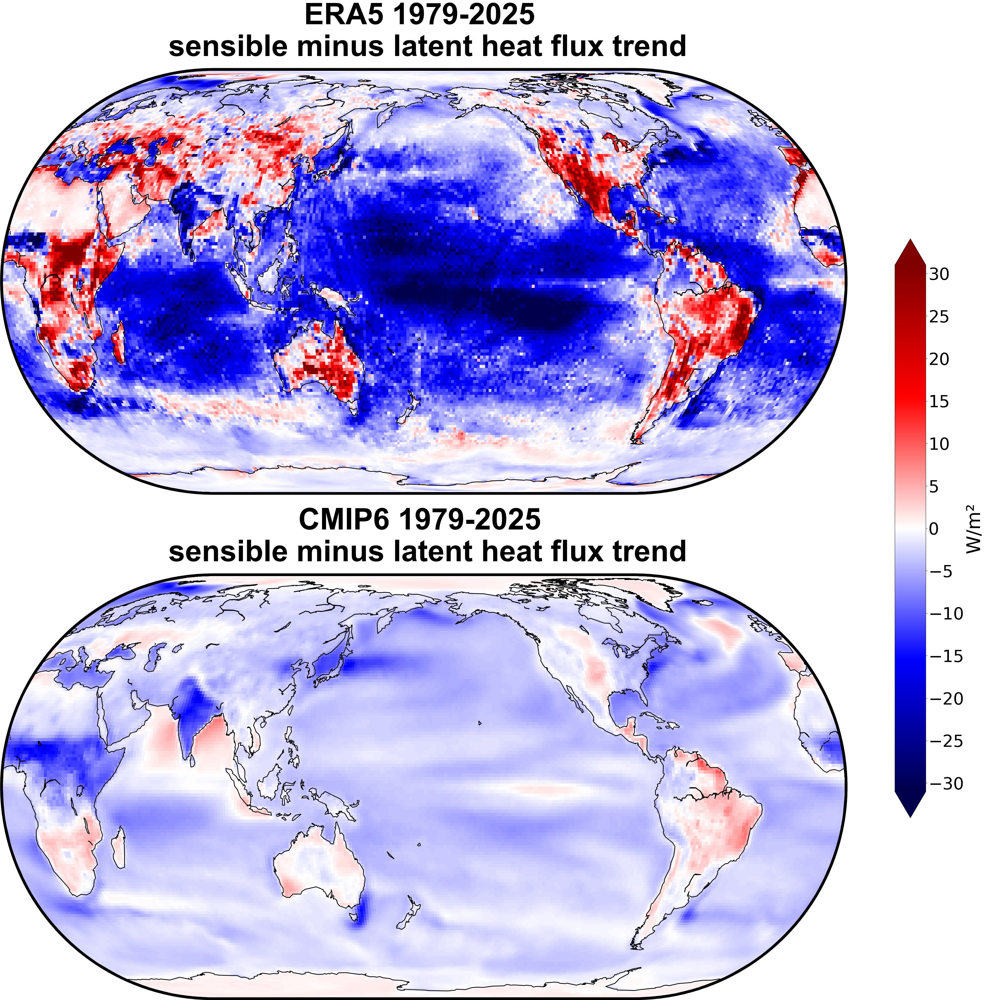

In [326]:
#Figure S5
Models = ['access_cm2','access_esm1_5','awi_cm_1_1_mr','bcc_csm2_mr','cams_csm1_0','canesm5',
          'canesm5_1','cesm2','cesm2_waccm','cmcc_cm2_sr5','cmcc_esm2',
          'cnrm_cm6_1_hr','cnrm_esm2_1','e3sm_1_0','ec_earth3_cc','ec_earth3_veg','ec_earth3_veg_lr',
          'fgoals_f3_l','fgoals_g3','fio_esm_2_0','gfdl_esm4','giss_e2_1_g','giss_e2_2_g',
          'iitm_esm','inm_cm4_8','inm_cm5_0','ipsl_cm6a_lr','hadgem3_gc31_ll','hadgem3_gc31_mm',
          'kace_1_0_g','mcm_ua_1_0','miroc6','miroc_es2l','mpi_esm1_2_hr','mpi_esm1_2_lr',
          'mri_esm2_0','nesm3','noresm2_mm','taiesm1','ukesm1_0_ll'] #Models with hfss/hfls available

Years = np.arange(1979,2015,1)
SHFLX_2014 = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'surface_upward_sensible_heat_flux',Years,Months,'SFC')
LHFLX_2014 = GetCMIP6_100km_Historical_TS_MultiModelMean(Models,'surface_upward_latent_heat_flux',Years,Months,'SFC')
Years = np.arange(2015,2026,1)
SHFLX_2025 = GetCMIP6_100km_TS_MultiModelMean(Models,'shflx',Years,Months,'SFC')
LHFLX_2025 = GetCMIP6_100km_TS_MultiModelMean(Models,'lhflx',Years,Months,'SFC')
SHFLX_CMIP6 = np.concatenate((SHFLX_2014,SHFLX_2025))
LHFLX_CMIP6 = np.concatenate((LHFLX_2014,LHFLX_2025))

Years = np.arange(1979,2026,1)
Months = [0,1,2,3,4,5,6,7,8,9,10,11]
MonthLengths = np.array([31,28,31,30,31,30,31,31,30,31,30,31])
ndays = np.sum(MonthLengths[Months])
MonthWeights = MonthLengths[Months]/ndays
Tinds = []
for Year in Years:
    for Month in Months:
        Tinds.append((Year-1979)*12+Month)

SHFLX_ERA5 = GetERA5_TS('sshf','SFC',Months,Years)/86400.
LHFLX_ERA5 = GetERA5_TS('slhf','SFC',Months,Years)/86400.


Years = np.arange(1979,2026,1)
Slopes_SHFLX_CMIP6,Pvals = GetRegression(SHFLX_CMIP6,Years)
Slopes_LHFLX_CMIP6,Pvals = GetRegression(LHFLX_CMIP6,Years)
Slopes_SHFLX_ERA5,Pvals = GetRegression(SHFLX_ERA5,Years)
Slopes_LHFLX_ERA5,Pvals = GetRegression(LHFLX_ERA5,Years)
Slopes_Diff_CMIP6 = Slopes_SHFLX_CMIP6 -Slopes_LHFLX_CMIP6
Slopes_Diff_ERA5 = Slopes_SHFLX_ERA5 -Slopes_LHFLX_ERA5
Slopes_Turbulent_CMIP6,Pvals = GetRegression(SHFLX_CMIP6-LHFLX_CMIP6,Years)
Slopes_Turbulent_ERA5,Pvals = GetRegression(SHFLX_ERA5-LHFLX_ERA5,Years)

fig = plt.figure(figsize=(50,43))
fig.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
ax = fig.add_subplot(2,1,2)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
m.pcolormesh(xx,yy,Slopes_Turbulent_CMIP6*len(Years),cmap='seismic',vmin=-31,vmax=31)
plt.title('CMIP6 1979-2025 \n sensible minus latent heat flux trend',fontsize=80,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=15, color='black')
boundary.set_clip_on(False)
[i.set_linewidth(4) for i in ax.spines.values()]

ax = fig.add_subplot(2,1,1)
m = Basemap(projection='eck4',lon_0=180,resolution='c')
x,y = np.meshgrid(lons_c96,lats_c96)
xx,yy = m(x,y)
m.drawcoastlines(linewidth=2)
f = m.pcolormesh(xx,yy,-1*Slopes_Turbulent_ERA5*len(Years),cmap='seismic',vmin=-31,vmax=31)
plt.title('ERA5 1979-2025 \n sensible minus latent heat flux trend',fontsize=80,y=1.03,fontweight='bold',fontname="Arial")
boundary = m.drawmapboundary(linewidth=15, color='black')
boundary.set_clip_on(False)
cbar_ax = fig.add_axes([0.85, 0.255, 0.023, 0.5])
cbar = fig.colorbar(f,cax=cbar_ax,fraction=0.0005,orientation='vertical',extend='both')
cbar.set_label('W/m\u00b2',fontsize=50)
cbar.ax.tick_params(labelsize=45)
cbar.set_ticks([-30,-25,-20,-15,-10,-5,0,5,10,15,20,25,30])
[i.set_linewidth(4) for i in ax.spines.values()]
plt.show() 